# 10.2.4 配套实验：反转学习中的 RW 与 GRU

在反转学习任务中，个体需要根据不断获得的奖励调整选择。经典强化学习模型用预先规定的规则描述这一过程，循环神经网络则通过拟合行为数据学习状态更新的方式。本实验以猴子的选择行为为例，比较 RW 模型与两隐藏单元 GRU 的预测，并分析两者在相同反馈下的状态变化。

完成本实验后，应能够将行为记录整理为保留实验块边界的序列，说明模型预测与反馈更新的时间关系，并结合测试表现和状态动力学讨论模型的学习规则。实验内容与教材第 10 章第 10.2.4 节对应。

## 1. 实验准备

数据来自 Bartolo 与 Averbeck（2022，见参考文献），将 `.mat` 文件放入本文件同级的 `data` 目录。默认分析猴子 V，分析猴子 W 时修改 `ANIMAL_NAME`。

使用 Python 3.13，通过 uv 创建环境并安装依赖：

```bash
uv venv --python 3.13
uv pip install numpy scipy matplotlib torch jupyterlab ipykernel
```

在本文件所在目录启动 Jupyter 并依次运行全部单元，即可完成数据整理、参数估计、测试评价与插图生成：

```bash
uv run jupyter lab reversal_learning.ipynb
```

In [1]:
import copy
from collections import Counter
from pathlib import Path

import matplotlib
import numpy as np
import scipy
import torch
from scipy.io import loadmat
from scipy.optimize import minimize
from torch import nn

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import SVG, Markdown, display
from matplotlib import font_manager
from matplotlib.patches import FancyArrowPatch
from matplotlib.ticker import MaxNLocator


def show_table(headers, rows):
    """将表头与记录显示为表格。"""
    lines = ["| " + " | ".join(headers) + " |"]
    lines.append("| " + " | ".join(["---"] * len(headers)) + " |")
    for row in rows:
        lines.append("| " + " | ".join(str(value) for value in row) + " |")
    display(Markdown("\n".join(lines)))


def show_svg(path):
    """显示本次实验生成的矢量插图。"""
    display(SVG(filename=str(path)))


In [2]:
# ── 数据位置 ─────────────────────────────────────────────
DATA_DIR = Path("data")
# 兼容数据位于上一级目录的资料排布。
if not DATA_DIR.is_dir() and Path("../data").is_dir():
    DATA_DIR = Path("../data")

# ── 数据与划分 ───────────────────────────────────────────
ANIMAL_NAME = "V"          # 猴子个体："V" 或 "W"。
TRIAL_START = 11           # 保留每个 block 的第 11–70 次试次（去掉开头学习期）。
TRIAL_END = 70
SEED = 0                   # 数据划分与 GRU 初始化的随机种子。
VALIDATION_FRACTION = 0.1  # 验证集占全部 block 的比例。
TEST_FRACTION = 0.1        # 测试集占全部 block 的比例。

# ── GRU 模型与训练 ───────────────────────────────────────
HIDDEN_DIM = 2             # 隐藏状态维度（本实验的二维动力学图要求为 2）。
LEARNING_RATE = 0.005      # AdamW 学习率。
MAX_EPOCHS = 1000          # 最多训练轮数。
PATIENCE = 100             # 验证损失连续多少轮未改善则提前停止。
L1_LAMBDA = 1e-4           # L1 正则化系数；权重绝对值之和乘以该系数加入损失。

# ── 动力学图网格 ─────────────────────────────────────────
GRID_SIZE = 41             # 状态平面网格每方向的点数。
MAX_ARROWS_PER_CONDITION = None  # 每种条件最多显示的箭头数；None 表示全部。
DYNAMICS_SAMPLE_SEED = 0   # 箭头抽样的随机种子。

# ── 图片输出目录 ─────────────────────────────────────────
FIGURE_DIR = Path("reversal_learning_results") / f"monkey_{ANIMAL_NAME}_seed{SEED}" / "figures"

if not DATA_DIR.is_dir():
    raise FileNotFoundError("未找到数据目录，请设置 DATA_DIR 后重新运行。")

In [3]:
MODEL_COLORS = {"RW": "#c97722", "GRU": "#2864ba"}
INK = "#26313c"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "text.color": INK,
    "axes.labelcolor": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
    "mathtext.fontset": "dejavusans",
})


def _save(figure, output_dir, filename):
    """导出 SVG 矢量图，并关闭图对象以释放内存。"""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    try:
        # Matplotlib 的色标可能默认栅格化；显式保留全部矢量元素。
        for artist in figure.findobj():
            if artist.get_rasterized():
                artist.set_rasterized(False)
        figure.savefig(
            output_dir / f"{filename}.svg", bbox_inches="tight", pad_inches=0.08,
        )
    finally:
        plt.close(figure)


def _publication_style():
    """主图使用统一的论文排版；作用域结束后恢复其余图的样式。"""
    return plt.rc_context(
        {
            "font.family": "DejaVu Sans",
            "font.size": 8,
            "axes.labelsize": 9,
            "axes.titlesize": 9,
            "axes.linewidth": 0.7,
            "axes.facecolor": "white",
            "axes.grid": False,
            "xtick.labelsize": 8,
            "ytick.labelsize": 8,
            "xtick.major.width": 0.7,
            "ytick.major.width": 0.7,
            "xtick.major.size": 3,
            "ytick.major.size": 3,
            "legend.fontsize": 8,
            "legend.frameon": False,
            "mathtext.fontset": "dejavusans",
        }
    )

## 2. 反转学习任务与行为数据

猴子在每次试次中选择两个选项之一，随后获得奖励或无奖励反馈。每个完整实验块（block）包含 80 次试次，两个选项的奖励概率分别为 0.7 和 0.3，并在 block 中部的一个随机试次无提示地互换（Bartolo 等，2020）。由于奖励具有概率性，一次无奖励并不足以确定环境已经发生反转。

任务包含两种条件：what block 的奖励概率与图像身份有关，where block 的奖励概率与空间位置有关。数据整理时分别依据图像或位置将选择编码为动作 0 和动作 1，奖励编码为 1，无奖励编码为 0。动作 0 的含义因任务条件而异。

数据文件按实验场次（session）保存，每个 session 包含多个 block。以下分析使用猴子 V 的 4 个 session，共 96 个完整 block。每个 block 保留原始第 11–70 次试次，共 60 次。模型在保留序列的起点将状态初始化为零，反转时继续更新；这一处理不包含前 10 次试次的行为历史。

### 读取行为记录

数据矩阵 `Y` 的每行对应一次试次。以下列号按 Python 从 0 开始计数：第 0、1 列分别记录图像与位置选择，第 2 列为奖励，第 5 列为原始试次编号，第 6 列为反转标记，第 7、8 列分别为任务条件编号与 session 内的 block 序号，第 9 列为任务类型，第 12 列表示 block 是否完成。

`load_session` 按 block 序号分组，保留任务条件编号在 1–24 且已完成的 block。反转位置从完整记录中提取，随后截取原始第 11–70 次试次。`load_blocks` 按文件名排序并汇总同一只猴子的多个 session。

In [4]:
def load_session(file_path, trial_start=11, trial_end=70):
    """从一个 MAT 文件中提取完整 block，保留指定编号范围内的试次。"""
    file_path = Path(file_path)
    behavior = loadmat(file_path, variable_names=["Y"])["Y"]

    # 文件名包含猴子名称和日期，例如 V20161005cue。
    session_token = file_path.stem.split("_")[1]
    animal_name = session_token[0]
    session_name = session_token.removesuffix("cue")

    # 以下列索引从 0 开始。BlockOrder 与 session_name 共同标识一个 block。
    block_orders = behavior[:, 8].astype(int)
    unique_orders = []
    for block_order in block_orders:
        if block_order not in unique_orders:
            unique_orders.append(block_order)

    blocks = []
    for block_order in unique_orders:
        rows = behavior[block_orders == block_order]
        block_id = int(rows[0, 7])
        block_completed = rows[:, 12] == 1
        if not (1 <= block_id <= 24) or not np.all(block_completed):
            continue

        trial_numbers = rows[:, 5].astype(int)
        task_type = int(rows[0, 9])
        block_type = "what" if task_type == 1 else "where"

        # 反转位置在截取前提取；它只用于标注，不作为模型输入。
        reversal_trials = trial_numbers[rows[:, 6] == 1]
        if len(reversal_trials) != 1:
            raise ValueError(f"{session_name} 的 block {block_order} 应有一次反转。")

        # what 任务按图像编码动作，where 任务按位置编码动作。
        action_column = 0 if task_type == 1 else 1
        actions = rows[:, action_column].astype(int)
        rewards = rows[:, 2].astype(int)
        selected = (trial_numbers >= trial_start) & (trial_numbers <= trial_end)

        blocks.append({
            "animal_name": animal_name,
            "session_name": session_name,
            "block_order": int(block_order),
            "block_type": block_type,
            "trial_numbers": trial_numbers[selected],
            "actions": actions[selected],
            "rewards": rewards[selected],
            "reversal_trial": int(reversal_trials[0]),
        })
    return blocks


def load_blocks(data_dir, animal_name, trial_start=11, trial_end=70):
    """汇总同一只猴子的全部 session，并保持固定的文件及 block 顺序。"""
    data_dir = Path(data_dir)
    pattern = f"SPKcounts_{animal_name}*cue_MW_250X250ms.mat"
    mat_files = sorted(data_dir.glob(pattern))
    if not mat_files:
        raise FileNotFoundError(f"在 {data_dir} 中未找到猴子 {animal_name} 的 MAT 数据。")

    blocks = []
    for file_path in mat_files:
        session_blocks = load_session(file_path, trial_start, trial_end)
        blocks.extend(session_blocks)
    return blocks

In [5]:
blocks = load_blocks(DATA_DIR, ANIMAL_NAME, TRIAL_START, TRIAL_END)
session_counts = Counter(block["session_name"] for block in blocks)
show_table(["session", "完整 block 数"], sorted(session_counts.items()))
print("合计 block 数：", len(blocks))
print("各 block 保留试次数：", sorted({len(block["actions"]) for block in blocks}))

example = blocks[0]
print("记录示例：", example["session_name"], "block", example["block_order"], example["block_type"])
rows = []
for t in range(min(10, len(example["actions"]))):
    rows.append([
        example["trial_numbers"][t],
        example["actions"][t],
        example["rewards"][t],
    ])
show_table(["原始试次编号", "动作 a", "奖励 r"], rows)

| session | 完整 block 数 |
| --- | --- |
| V20160929 | 24 |
| V20160930 | 24 |
| V20161005 | 24 |
| V20161017 | 24 |

合计 block 数： 96
各 block 保留试次数： [60]
记录示例： V20160929 block 1 where


| 原始试次编号 | 动作 a | 奖励 r |
| --- | --- | --- |
| 11 | 0 | 0 |
| 12 | 0 | 1 |
| 13 | 0 | 1 |
| 14 | 0 | 0 |
| 15 | 0 | 0 |
| 16 | 1 | 0 |
| 17 | 0 | 0 |
| 18 | 1 | 0 |
| 19 | 1 | 0 |
| 20 | 0 | 0 |

## 3. 数据划分与输入格式

训练集用于估计参数，验证集用于选择 GRU 的训练停止时机，测试集用于评价最终预测。数据按完整 block 划分，各 block 内的试次顺序保持不变。默认随机种子下，三个集合分别包含 78、9 和 9 个 block。

一个 block 由猴子编号、session 名称和该 session 内的 block 序号共同标识。下列代码检查三个集合的 block 是否互不重叠，并统计各集合的试次数。

In [6]:
def block_ids(blocks):
    """返回 block 的唯一标识，供数据划分核对使用。"""
    return [
        (block["animal_name"], block["session_name"], block["block_order"])
        for block in blocks
    ]


def split_blocks(blocks, validation_fraction=0.1, test_fraction=0.1, seed=0):
    """以完整 block 为单位划分训练、验证和测试集。"""
    n_blocks = len(blocks)
    n_validation = int(n_blocks * validation_fraction)
    n_test = int(n_blocks * test_fraction)
    n_train = n_blocks - n_validation - n_test

    # 只打乱 block 的排列，保留每个 block 内部的试次顺序。
    rng = np.random.default_rng(seed)
    indices = np.arange(n_blocks)
    rng.shuffle(indices)
    train_indices = indices[:n_train]
    validation_indices = indices[n_train:n_train + n_validation]
    test_indices = indices[n_train + n_validation:]

    train_blocks = [blocks[i] for i in train_indices]
    validation_blocks = [blocks[i] for i in validation_indices]
    test_blocks = [blocks[i] for i in test_indices]
    return train_blocks, validation_blocks, test_blocks


def prepare_batch(blocks, model):
    """把等长 block 整理成 inputs (T, B, 2) 与 targets (T, B)。"""
    block_inputs = []
    for block in blocks:
        inputs = np.stack([block["actions"], block["rewards"]], axis=-1)
        block_inputs.append(inputs)
    inputs = np.stack(block_inputs, axis=1)
    targets = np.stack([block["actions"] for block in blocks], axis=1)

    parameter = next(model.parameters())
    inputs = torch.tensor(inputs, dtype=parameter.dtype, device=parameter.device)
    targets = torch.tensor(targets, dtype=torch.long, device=parameter.device)
    return inputs, targets

In [7]:
train_blocks, validation_blocks, test_blocks = split_blocks(
    blocks,
    validation_fraction=VALIDATION_FRACTION,
    test_fraction=TEST_FRACTION,
    seed=SEED,
)
splits = {"train": train_blocks, "validation": validation_blocks, "test": test_blocks}

show_table(
    ["集合", "block 数", "试次数"],
    [[name, len(group), sum(len(block["actions"]) for block in group)] for name, group in splits.items()],
)

| 集合 | block 数 | 试次数 |
| --- | --- | --- |
| train | 78 | 4680 |
| validation | 9 | 540 |
| test | 9 | 540 |

GRU 的批量输入形状为 `(T, B, 2)`：T 个试次、B 个 block、最后一维为 `[动作, 奖励]`；`targets` 形状 `(T, B)`。不同 block 沿批量维度排列，各自保持独立的状态序列。预测当前动作只能使用此前的行为历史，由后文的状态对齐实现。

In [8]:
train_inputs = np.stack(
    [np.stack([block["actions"], block["rewards"]], axis=-1) for block in train_blocks],
    axis=1,
)
train_targets = np.stack([block["actions"] for block in train_blocks], axis=1)

print("inputs：", train_inputs.shape)
print("targets：", train_targets.shape)
print("第一个训练 block 的前 5 组 [动作, 奖励]：")
print(train_inputs[:5, 0, :])

inputs： (60, 78, 2)
targets： (60, 78)
第一个训练 block 的前 5 组 [动作, 奖励]：
[[1 0]
 [0 0]
 [0 1]
 [1 0]
 [0 1]]


## 4. RW 模型：价值预测与反馈更新

令 $Q_t(a)$ 表示第 $t$ 次选择前对动作 $a$ 的价值估计。模型将两个动作的价值通过 softmax 转换为选择概率：

$$
p_t(a)=\frac{\exp[\beta Q_t(a)]}{\exp[\beta Q_t(0)]+\exp[\beta Q_t(1)]}
$$

其中，逆温度 $\beta$ 控制选择对价值差异的敏感程度。观察到动作 $a_t$ 与奖励 $r_t$ 后，被选动作的价值更新为

$$
Q_{t+1}(a_t)=Q_t(a_t)+\alpha[r_t-Q_t(a_t)]
$$

未选动作的价值保持不变。学习率 $\alpha$ 决定新反馈对价值估计的影响。代码中的 `iTemp` 对应逆温度 $\beta$。

`RWModel.predict_block` 将选择预测与价值更新写在同一循环中。每次循环先保存当前状态并计算选择概率，再读取该试次的动作与奖励。所有训练 block 共同确定 $\alpha$ 和 $\beta$，各 block 的价值状态则独立演化。

In [9]:
class RWModel:
    """以两个选项的价值预测选择；alpha 与 iTemp 在所有 block 间共享。"""

    def __init__(self, alpha=0.5, iTemp=5.0):
        self.alpha = alpha
        self.iTemp = iTemp

    def choice_probabilities(self, values):
        """将两个价值转换为选择概率，返回 [P(a=0), P(a=1)]。"""
        values = np.asarray(values, dtype=float)
        # 减去最大值可以避免指数溢出，不改变 softmax 的结果。
        scores = self.iTemp * (values - values.max())
        weights = np.exp(scores)
        return weights / weights.sum()

    def update_values(self, values, action, reward):
        """只更新被选择的选项，并保留输入的旧价值。"""
        new_values = values.copy()
        prediction_error = reward - new_values[action]
        new_values[action] += self.alpha * prediction_error
        return new_values

    def predict_block(self, actions, rewards):
        """先预测当前选择，再读取当前动作与奖励；每个 block 从零开始。"""
        values = np.zeros(2, dtype=float)
        probabilities = []
        states = []
        for t in range(len(actions)):
            states.append(values.copy())
            probabilities.append(self.choice_probabilities(values))
            values = self.update_values(values, actions[t], rewards[t])

        return {
            "probabilities": np.array(probabilities),
            "states": np.array(states),
            "final_state": values.copy(),
        }

    def update_state(self, state, action, reward):
        """从给定价值出发更新一步，供动力学分析使用。"""
        values = np.asarray(state, dtype=float)
        return self.update_values(values, action, reward)

## 5. GRU 模型：隐藏状态与门控更新

GRU 用隐藏状态 $\mathbf h_t$ 概括此前的行为历史。本实验将隐藏维度设为 2，并通过线性读出层产生两个动作分数，再用 softmax 得到选择概率：

$$
\mathbf p_t=\operatorname{softmax}(W_{\mathrm{out}}\mathbf h_t+\mathbf b_{\mathrm{out}})
$$

模型由 `nn.GRU(input_size=2, hidden_size=2)` 和 `nn.Linear(2, 2)` 组成，共有 42 个可训练参数。二维状态便于在平面上观察更新过程，但两个隐藏坐标没有预先指定的价值含义。

GRU 读取本次输入 $\mathbf x_t=(a_t,r_t)^\mathsf T$ 后，输出的是下一状态 $\mathbf h_{t+1}$。预测当前动作时，应使用读取该输入之前的 $\mathbf h_t$。因此，`GRUModel.forward` 在状态序列开头加入零初始状态，并移除最后一项，使状态与预测目标正确对应。

In [10]:
class GRUModel(nn.Module):
    """输入为动作与奖励，以二维隐藏状态预测两个动作的分数。"""

    def __init__(self, hidden_dim=2):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.gru = nn.GRU(input_size=2, hidden_size=hidden_dim, batch_first=False)
        self.linear = nn.Linear(hidden_dim, 2)

    def forward(self, inputs):
        """输入 (T, B, 2)，返回预测分数及状态；保留参数梯度供训练使用。"""
        # B 个 block 各有独立的零初始状态，不在 block 之间传递记忆。
        h0 = torch.zeros(
            1, inputs.size(1), self.hidden_dim,
            dtype=inputs.dtype, device=inputs.device,
        )
        updated_states, final_state = self.gru(inputs, h0)

        # 当前预测只能使用此前的事件：在开头加入 h0，移去最后一个更新后状态。
        states = torch.cat([h0, updated_states[:-1]], dim=0)
        logits = self.linear(states)
        return {
            "logits": logits,
            "states": states,
            "final_state": final_state.squeeze(0),
        }

    def predict_block(self, actions, rewards):
        """评估单个 block，返回 NumPy 格式的选择概率与状态轨迹。"""
        parameter = next(self.parameters())
        inputs = np.stack([actions, rewards], axis=-1)
        inputs = torch.tensor(inputs, dtype=parameter.dtype, device=parameter.device)
        inputs = inputs.unsqueeze(1)  # (T, 1, 2)

        self.eval()
        with torch.no_grad():
            result = self(inputs)
            probabilities = torch.softmax(result["logits"], dim=-1)
        return {
            "probabilities": probabilities[:, 0].cpu().numpy(),
            "states": result["states"][:, 0].cpu().numpy(),
            "final_state": result["final_state"][0].cpu().numpy(),
        }

    def update_state(self, state, action, reward):
        """从指定隐藏状态读取一次事件，不执行 block 的零初始化。"""
        parameter = next(self.parameters())
        hidden = torch.tensor(state, dtype=parameter.dtype, device=parameter.device)
        hidden = hidden.reshape(1, 1, self.hidden_dim)
        inputs = torch.tensor(
            [[[action, reward]]], dtype=parameter.dtype, device=parameter.device,
        )
        self.eval()
        with torch.no_grad():
            _, next_hidden = self.gru(inputs, hidden)
        return next_hidden[0, 0].cpu().numpy()

    def choice_probabilities(self, state):
        """从给定隐藏状态读出两个动作的概率，不更新状态。"""
        parameter = next(self.parameters())
        hidden = torch.tensor(state, dtype=parameter.dtype, device=parameter.device)
        with torch.no_grad():
            logits = self.linear(hidden)
            probabilities = torch.softmax(logits, dim=-1)
        return probabilities.cpu().numpy()

GRU 通过重置门与更新门调节历史信息；两个门均依赖当前输入和旧状态，因此相同反馈可以在不同历史状态下产生不同更新。

## 6. 参数估计

两种模型均以提高真实选择的预测概率为目标。RW 在训练集上估计 $\alpha$ 和 $\beta$；GRU 通过反向传播更新权重，并保留验证集负对数似然最低时的参数。测试集用于拟合结束后的评价。

应区分参数估计与任务中的状态变化：训练时，GRU 的权重随优化过程改变；分析行为时，权重固定，隐藏状态随动作与奖励逐次更新。代码中的 `LEARNING_RATE` 控制优化器的步长，与 RW 学习率 $\alpha$ 的行为含义不同。

`RWModel` 与 `GRUModel` 封装了前述更新规则，`fit_rw` 与 `fit_gru` 完成参数估计。以下给出两种优化过程的完整实现，并从初始参数开始拟合。训练 NLL 记录每轮参数更新前的损失，验证 NLL 记录该轮更新后的损失；训练结束时恢复验证 NLL 最低的权重。

负对数似然取真实动作对应概率的负对数。`evaluate` 按试次数加权汇总各 block 的指标，保持各 block 的状态独立初始化。

In [11]:
def negative_log_likelihood(probabilities, actions):
    """真实选择对应的平均负对数似然，使用自然对数。"""
    true_probabilities = probabilities[np.arange(len(actions)), actions]
    true_probabilities = np.clip(true_probabilities, 1e-10, None)
    return -np.mean(np.log(true_probabilities))


def accuracy(probabilities, actions):
    """预测动作与猴子实际动作相同的比例；概率相同时选动作 0。"""
    predicted_actions = np.argmax(probabilities, axis=1)
    return np.mean(predicted_actions == actions)


def evaluate(model, blocks):
    """独立预测各 block，再按试次数加权汇总指标。"""
    total_nll = []
    total_correct = []
    total_trials = 0
    for block in blocks:
        actions = block["actions"]
        prediction = model.predict_block(actions, block["rewards"])
        probabilities = prediction["probabilities"]
        n_trials = len(actions)
        total_nll.append(negative_log_likelihood(probabilities, actions) * n_trials)
        total_correct.append(accuracy(probabilities, actions) * n_trials)
        total_trials += n_trials
    return {
        "n_trials": total_trials,
        "nll": float(np.sum(total_nll) / total_trials),
        "accuracy": float(np.sum(total_correct) / total_trials),
    }

### RW 参数估计

优化变量为学习率和逆温度。每次计算目标函数时，各训练 block 均从零价值开始。

In [12]:
def fit_rw(model, train_blocks):
    """最小化训练集平均负对数似然，将拟合后的 alpha、iTemp 写入模型。"""
    def objective(parameters):
        model.alpha, model.iTemp = parameters
        total_nll = 0.0
        total_trials = 0
        for block in train_blocks:
            actions = block["actions"]
            probabilities = model.predict_block(actions, block["rewards"])["probabilities"]
            n_trials = len(actions)
            total_nll += negative_log_likelihood(probabilities, actions) * n_trials
            total_trials += n_trials
        return total_nll / total_trials

    result = minimize(
        objective,
        x0=[0.5, 1.0],
        bounds=[(0, 1), (1e-8, None)],
        method="L-BFGS-B",
    )
    if not result.success:
        raise RuntimeError(f"RW 参数优化失败：{result.message}")
    model.alpha, model.iTemp = result.x

### GRU 参数估计

每轮将全部训练 block 的预测损失反向传播一次。验证损失连续若干轮未改善时停止训练，`PATIENCE` 指定这一轮数。

In [13]:
def fit_gru(
    model, train_blocks, validation_blocks,
    learning_rate=0.005, max_epochs=1000, patience=100, l1_lambda=1e-4,
):
    """使用训练集更新权重，以验证集选择停止时机，恢复最佳验证权重。"""
    train_inputs, train_targets = prepare_batch(train_blocks, model)
    validation_inputs, validation_targets = prepare_batch(validation_blocks, model)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=0)
    criterion = nn.CrossEntropyLoss()
    best_validation_loss = float("inf")
    best_state = None
    epochs_without_improvement = 0
    history = {
        "epoch": [],
        "train_nll": [],
        "validation_nll": [],
        "best_epoch": 0,
    }

    for epoch in range(1, max_epochs + 1):
        # 一轮使用所有训练 block；交叉熵在全部试次上取平均。
        model.train()
        optimizer.zero_grad()
        logits = model(train_inputs)["logits"]
        train_loss = criterion(logits.reshape(-1, 2), train_targets.reshape(-1))
        # L1 惩罚：对全部权重取绝对值求和，促使部分连接变为零。
        l1_penalty = sum(p.abs().sum() for p in model.parameters())
        train_loss = train_loss + l1_lambda * l1_penalty
        train_loss.backward()
        optimizer.step()

        # 验证集只参与停止时机的选择，不用于计算参数更新的梯度。
        model.eval()
        with torch.no_grad():
            logits = model(validation_inputs)["logits"]
            validation_loss = criterion(
                logits.reshape(-1, 2), validation_targets.reshape(-1),
            ).item()

        history["epoch"].append(epoch)
        history["train_nll"].append(train_loss.item())
        history["validation_nll"].append(validation_loss)
        if validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            best_state = copy.deepcopy(model.state_dict())
            history["best_epoch"] = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epoch == 1 or epoch % 100 == 0:
            print(
                f"第 {epoch:4d} 轮：训练 NLL = {train_loss.item():.4f}，"
                f"验证 NLL = {validation_loss:.4f}"
            )
        if epochs_without_improvement >= patience:
            break

    if best_state is None:
        raise RuntimeError("未得到有效的验证损失，请检查数据和训练参数。")
    model.load_state_dict(best_state)
    print(f"训练结束：恢复第 {history['best_epoch']} 轮的权重，验证 NLL = {best_validation_loss:.4f}。")
    return history

In [14]:
rw_model = RWModel()
print("估计 RW 参数……", flush=True)
fit_rw(rw_model, train_blocks)

# 固定初始化种子；模型与输入均使用 CPU。
torch.manual_seed(SEED)
gru_model = GRUModel(hidden_dim=HIDDEN_DIM)
print("估计 GRU 参数……", flush=True)
history = fit_gru(
    gru_model,
    train_blocks,
    validation_blocks,
    learning_rate=LEARNING_RATE,
    max_epochs=MAX_EPOCHS,
    patience=PATIENCE,
    l1_lambda=L1_LAMBDA,
)
models = {"RW": rw_model, "GRU": gru_model}
print(f"RW：alpha = {rw_model.alpha:.6f}，iTemp = {rw_model.iTemp:.6f}")
print("GRU 参数数量：", sum(parameter.numel() for parameter in gru_model.parameters()))
print("验证 NLL 最低的训练轮次：", history["best_epoch"])

估计 RW 参数……
估计 GRU 参数……
第    1 轮：训练 NLL = 0.7690，验证 NLL = 0.8038
第  100 轮：训练 NLL = 0.5492，验证 NLL = 0.4881
第  200 轮：训练 NLL = 0.4439，验证 NLL = 0.3350
第  300 轮：训练 NLL = 0.4211，验证 NLL = 0.3121
第  400 轮：训练 NLL = 0.4085，验证 NLL = 0.3029
第  500 轮：训练 NLL = 0.4004，验证 NLL = 0.2943
第  600 轮：训练 NLL = 0.3979，验证 NLL = 0.2930
训练结束：恢复第 534 轮的权重，验证 NLL = 0.2929。
RW：alpha = 0.445283，iTemp = 3.387289
GRU 参数数量： 42
验证 NLL 最低的训练轮次： 534


## 7. 选择预测与状态轨迹

参数确定后，分别计算各测试 block 的逐试次选择概率和内部状态。`states[t]` 表示第 $t$ 次反馈前的状态，`final_state` 保存最后一次反馈后的状态。一个包含 $T$ 次试次的 block 因而对应 $T$ 组预测与 $T+1$ 个状态位置。

这些记录同时用于预测评价和动力学分析。

In [15]:
def collect_predictions(models, blocks):
    """保存各 block 的真实事件、预测概率和完整状态轨迹。"""
    records = []
    for block in blocks:
        record = block.copy()
        record["models"] = {}
        for model_name, model in models.items():
            record["models"][model_name] = model.predict_block(
                block["actions"], block["rewards"],
            )
        records.append(record)
    return records


def summarize_model_comparison(records):
    """在同一只猴子的全部测试试次上比较 RW 与 GRU。"""
    actions = np.concatenate([record["actions"] for record in records])
    comparison = {
        "animal_name": records[0]["animal_name"],
        "n_blocks": len(records),
        "n_sessions": len({record["session_name"] for record in records}),
        "n_trials": len(actions),
        "models": {},
    }
    for model_name in ("RW", "GRU"):
        block_probabilities = []
        for record in records:
            probabilities = record["models"][model_name]["probabilities"]
            block_probabilities.append(probabilities)
        # 此处拼接已计算的概率；各 block 的状态始终独立演化。
        probabilities = np.concatenate(block_probabilities)
        comparison["models"][model_name] = {
            "nll": float(negative_log_likelihood(probabilities, actions)),
            "accuracy": float(accuracy(probabilities, actions)),
        }
    return comparison

records = collect_predictions(models, test_blocks)

## 8. 测试集上的预测表现

预测评价使用每试次平均负对数似然（negative log-likelihood，NLL）：

$$
\mathrm{NLL}=-\frac{1}{N}\sum_{t=1}^{N}\ln p_t(a_t)
$$

其中，$N$ 为测试试次数，$p_t(a_t)$ 为模型赋予真实选择的概率。NLL 越低，表示模型整体上为真实选择分配的概率越高。

选择准确率统计预测概率最大的动作与真实动作相同的比例。与准确率相比，NLL 还反映预测的确信程度。两个指标均按测试试次汇总，用于比较同一组行为数据上的预测表现。

In [16]:
def plot_model_comparison(comparison: dict, output_dir: str | Path) -> None:
    """比较同一测试集的预测；样本信息和结论范围放在独立图注中。"""
    model_names = ["RW", "GRU"]
    nll_values = [comparison["models"][name]["nll"] for name in model_names]
    accuracy_values = [
        100 * comparison["models"][name]["accuracy"] for name in model_names
    ]
    colors = [MODEL_COLORS[name] for name in model_names]

    with _publication_style():
        figure, axes = plt.subplots(1, 2, figsize=(7.0, 2.7))
        figure.subplots_adjust(
            left=0.09, right=0.985, bottom=0.18, top=0.90, wspace=0.45
        )
        for panel, axis, values in zip("ab", axes, (nll_values, accuracy_values)):
            bars = axis.bar(model_names, values, width=0.55, color=colors)
            axis.margins(x=0.26)
            axis.text(
                -0.20,
                1.04,
                panel,
                transform=axis.transAxes,
                fontsize=10,
                fontweight="bold",
                va="bottom",
            )
            for bar, value in zip(bars, values):
                number = f"{value:.3f}" if axis is axes[0] else f"{value:.1f}"
                axis.annotate(
                    number,
                    xy=(bar.get_x() + bar.get_width() / 2, value),
                    xytext=(0, 4),
                    textcoords="offset points",
                    ha="center",
                    va="bottom",
                    fontsize=8,
                )

        # 柱状图保留零基线，不借截断纵轴放大模型之间的差异。
        axes[0].set_ylim(0, max(max(nll_values) * 1.22, 0.1))
        axes[0].yaxis.set_major_locator(MaxNLocator(nbins=5))
        axes[0].set_ylabel("Test NLL")
        axes[1].set_ylim(0, 100)
        axes[1].set_yticks(np.arange(0, 101, 20))
        axes[1].set_ylabel("Accuracy (%)")
        _save(figure, output_dir, "model_comparison")

| 模型 | 测试试次数 | 平均 NLL | 选择准确率 |
| --- | --- | --- | --- |
| RW | 540 | 0.400852 | 82.22% |
| GRU | 540 | 0.367496 | 84.44% |

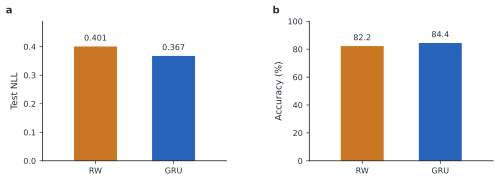

In [17]:
metrics = {}
for model_name, model in models.items():
    metrics[model_name] = evaluate(model, test_blocks)

show_table(
    ["模型", "测试试次数", "平均 NLL", "选择准确率"],
    [
        [name, score["n_trials"], f"{score['nll']:.6f}", f"{score['accuracy']:.2%}"]
        for name, score in metrics.items()
    ],
)
comparison = summarize_model_comparison(records)
plot_model_comparison(comparison, FIGURE_DIR)
show_svg(FIGURE_DIR / "model_comparison.svg")

**图 1　测试集预测表现。** 两个模型评价同一组测试试次。平均 NLL 越低，表示模型整体上赋予真实选择的概率越高；选择准确率越高，表示预测正确的试次比例越大。

## 9. 条件状态动力学

预测表现说明模型能否描述行为，状态动力学进一步揭示这种预测如何由内部更新产生。固定拟合后的参数，将一次更新写为

$$
\mathbf s_{t+1}=F_{a,r}(\mathbf s_t),\qquad
\Delta\mathbf s=F_{a,r}(\mathbf s_t)-\mathbf s_t
$$

RW 的状态为 $(Q(0),Q(1))$，GRU 的状态为 $(h_1,h_2)$。动作和奖励均取 0 或 1，因此共有四种输入条件。将全部测试 block 中属于同一条件的更新汇总，可以观察相同反馈在不同起始状态下的作用。

状态差分在各 block 内分别计算。末状态用于补全最后一次更新，不同 block 之间的初始化过程不计为学习更新。

In [18]:
# 分别计算各 block 内的状态差，再汇总测试事件。
observed_updates = {}
for model_name in models:
    changes_by_block = []
    for record in records:
        prediction = record["models"][model_name]
        complete_states = np.vstack([
            prediction["states"],
            prediction["final_state"],
        ])
        changes = complete_states[1:] - complete_states[:-1]
        changes_by_block.append(changes)
    observed_updates[model_name] = np.concatenate(changes_by_block)
    print(model_name, "状态更新数组形状：", observed_updates[model_name].shape)

event_counts = Counter()
for record in records:
    event_counts.update(zip(record["actions"].tolist(), record["rewards"].tolist()))
show_table(
    ["动作 a", "奖励 r", "整个测试集的事件数"],
    [[action, reward, event_counts[(action, reward)]] for action, reward in [(0, 0), (0, 1), (1, 0), (1, 1)]],
)

RW 状态更新数组形状： (540, 2)
GRU 状态更新数组形状： (540, 2)


| 动作 a | 奖励 r | 整个测试集的事件数 |
| --- | --- | --- |
| 0 | 0 | 101 |
| 0 | 1 | 188 |
| 1 | 0 | 116 |
| 1 | 1 | 135 |

`get_readout` 给出动作 0 相对动作 1 的分数差，用于确定等概率边界。`compute_vector_field` 在状态网格上计算四种输入的条件更新；`compute_model_dynamics` 将这些更新与全部测试 block 的实际事件相对应。

In [19]:
def get_readout(model):
    """返回两个动作分数之差中的权重与偏置：d(s) = w · s + b。

    d(s) = 0 是两个动作等概率的边界；d(s) > 0 时，动作 0 的概率更高。
    """
    if isinstance(model, RWModel):
        readout_vector = np.array([model.iTemp, -model.iTemp], dtype=float)
        readout_bias = 0.0
    else:
        weights = model.linear.weight.detach().cpu().numpy()
        biases = model.linear.bias.detach().cpu().numpy()
        readout_vector = np.asarray(weights[0] - weights[1], dtype=float)
        readout_bias = float(biases[0] - biases[1])
    return readout_vector, readout_bias

In [20]:
def compute_vector_field(model, states, grid_size=41, state_limits=None):
    """在状态网格上分别计算四种动作与奖励组合的一步更新。

    states 包含测试集中实际出现的状态，只用于确定网格范围。
    网格点未必被实际访问；背景颜色表示假设处于该点时的更新幅度。
    """
    states = np.asarray(states, dtype=float)
    readout_vector, readout_bias = get_readout(model)

    # 从全部状态的范围出发留出少量边距，再限制在模型的有效状态区间内。
    lower = states.min(axis=0)
    upper = states.max(axis=0)
    padding = np.maximum((upper - lower) * 0.12, 0.05)
    lower = lower - padding
    upper = upper + padding
    if state_limits is not None:
        lower = np.maximum(lower, state_limits[0])
        upper = np.minimum(upper, state_limits[1])

    x_values = np.linspace(lower[0], upper[0], grid_size)
    y_values = np.linspace(lower[1], upper[1], grid_size)
    x_grid, y_grid = np.meshgrid(x_values, y_values)
    points = np.column_stack([x_grid.ravel(), y_grid.ravel()])

    # 选择概率可用于其他分析；本实验的动力学背景使用下方计算的更新幅度。
    probabilities = []
    for state in points:
        probabilities.append(model.choice_probabilities(state)[0])
    probability_grid = np.asarray(probabilities).reshape(x_grid.shape)

    conditions = []
    for action in (0, 1):
        for reward in (0, 1):
            changes = []
            for state in points:
                next_state = model.update_state(state, action, reward)
                changes.append(next_state - state)
            changes = np.asarray(changes)

            # 更新向量给出方向，欧氏长度给出背景颜色及等值线的数值。
            speed = np.linalg.norm(changes, axis=1).reshape(x_grid.shape)
            conditions.append(
                {
                    "action": action,
                    "reward": reward,
                    "dx": changes[:, 0].reshape(x_grid.shape),
                    "dy": changes[:, 1].reshape(y_grid.shape),
                    "speed": speed,
                    "observed_states": np.empty((0, 2)),
                    "observed_changes": np.empty((0, 2)),
                }
            )

    # 同一模型的四个面板共享色标；不同模型的坐标单位不同，分别设定色标。
    speed_max = max(float(condition["speed"].max()) for condition in conditions)
    return {
        "x": x_grid,
        "y": y_grid,
        "probability": probability_grid,
        "conditions": conditions,
        "observed_states": states.copy(),
        "speed_max": speed_max,
        "readout_vector": readout_vector,
        "readout_bias": readout_bias,
    }

In [21]:
def compute_model_dynamics(
    model,
    records,
    model_name,
    grid_size=41,
    state_limits=None,
    max_arrows_per_condition=None,
    sample_seed=0,
):
    """固定模型参数，汇总整个测试集的状态更新。

    每个 block 内先计算相邻状态的差，再将不同 block 的结果合并。
    默认保留全部事件；如设置箭头数量上限，抽样仅影响箭头显示。
    """
    all_states = []
    update_starts = []
    update_changes = []
    all_actions = []
    all_rewards = []
    for record in records:
        prediction = record["models"][model_name]
        states = np.asarray(prediction["states"], dtype=float)
        final_state = np.asarray(prediction["final_state"], dtype=float)
        actions = np.asarray(record["actions"])
        rewards = np.asarray(record["rewards"])

        # states[t] 是反馈前的状态；补入 final_state 才能包含最后一次更新。
        # 不对拼接后的多 block 轨迹求差，避免把 block 间的重置误当成学习。
        complete_states = np.vstack([states, final_state])
        # 前一个去掉第一个state，后一个去掉最后一个state，得到相邻状态的差。
        changes = complete_states[1:] - complete_states[:-1]
        all_states.append(complete_states)
        update_starts.append(states)
        update_changes.append(changes)
        all_actions.append(actions)
        all_rewards.append(rewards)

    # 全部实际状态共同确定网格范围，其中包含每个 block 的最终状态。
    field = compute_vector_field(
        model,
        np.concatenate(all_states),
        grid_size=grid_size,
        state_limits=state_limits,
    )
    starts = np.concatenate(update_starts)
    changes = np.concatenate(update_changes)
    actions = np.concatenate(all_actions)
    rewards = np.concatenate(all_rewards)

    rng = np.random.default_rng(sample_seed)
    for condition in field["conditions"]:
        selected = (actions == condition["action"]) & (rewards == condition["reward"])
        event_indices = np.flatnonzero(selected)
        n_observed = len(event_indices)
        if max_arrows_per_condition is not None and n_observed > max_arrows_per_condition:
            event_indices = np.sort(
                rng.choice(event_indices, size=max_arrows_per_condition, replace=False)
            )

        # 同一索引同时提取更新起点和变化量；相同种子使两个模型抽到相同事件。
        condition["observed_states"] = starts[event_indices].copy()
        condition["observed_changes"] = changes[event_indices].copy()

    return field

In [22]:
def _decision_boundary_segment(
    readout_vector: np.ndarray,
    readout_bias: float,
    x_limits: tuple[float, float],
    y_limits: tuple[float, float],
) -> np.ndarray:
    """求 w·state+b=0 与可视矩形的交点，不把边界误写成经过原点。

    直接求四条边上的交点，也适用于水平或竖直的决策边界。
    如果读出权重为零，或边界没有穿过当前区域，就不画这条线。
    """
    vector_length = np.linalg.norm(readout_vector)
    if vector_length == 0:
        return np.empty((0, 2))
    normal = readout_vector / vector_length
    offset = readout_bias / vector_length
    x_min, x_max = x_limits
    y_min, y_max = y_limits
    tolerance = 1e-10 * max(x_max - x_min, y_max - y_min, 1.0)
    candidates = []

    if abs(normal[1]) > 1e-12:
        for x_value in x_limits:
            y_value = -(normal[0] * x_value + offset) / normal[1]
            if y_min - tolerance <= y_value <= y_max + tolerance:
                candidates.append([x_value, float(np.clip(y_value, y_min, y_max))])
    if abs(normal[0]) > 1e-12:
        for y_value in y_limits:
            x_value = -(normal[1] * y_value + offset) / normal[0]
            if x_min - tolerance <= x_value <= x_max + tolerance:
                candidates.append([float(np.clip(x_value, x_min, x_max)), y_value])

    # 经过矩形角点时，同一个交点可能被两条边同时找到。
    unique_points = []
    for candidate in candidates:
        already_found = any(
            np.linalg.norm(np.asarray(candidate) - point) <= tolerance
            for point in unique_points
        )
        if not already_found:
            unique_points.append(np.asarray(candidate))
    if len(unique_points) < 2:
        return np.empty((0, 2))
    return np.asarray(unique_points[:2])


def plot_dynamics_panel(axis, field, event, model_name):
    """在单个坐标轴上画一种条件下的一个模型：背景、等值线、箭头、决策边界。

    返回背景填色对象，供外部添加色标。
    """
    conditions = {
        (condition["action"], condition["reward"]): condition
        for condition in field["conditions"]
    }
    condition = conditions[event]
    grid_x = np.asarray(field["x"])
    grid_y = np.asarray(field["y"])
    all_states = np.asarray(field["observed_states"])
    speed = np.asarray(condition["speed"])
    speed_max = float(field["speed_max"])
    color_max = speed_max if speed_max > 0 else 1.0

    x_min = min(float(grid_x.min()), float(all_states[:, 0].min()))
    x_max = max(float(grid_x.max()), float(all_states[:, 0].max()))
    y_min = min(float(grid_y.min()), float(all_states[:, 1].min()))
    y_max = max(float(grid_y.max()), float(all_states[:, 1].max()))
    x_margin = 0.02 * max(x_max - x_min, 0.1)
    y_margin = 0.02 * max(y_max - y_min, 0.1)
    x_limits = (x_min - x_margin, x_max + x_margin)
    y_limits = (y_min - y_margin, y_max + y_margin)

    base_colors = matplotlib.colormaps["viridis"](np.linspace(0, 1, 256))[:, :3]
    pale_colormap = matplotlib.colors.ListedColormap(0.73 + 0.27 * base_colors)
    background = axis.contourf(
        grid_x, grid_y, speed,
        levels=np.linspace(0, color_max, 257),
        cmap=pale_colormap, vmin=0, vmax=color_max, antialiased=False,
    )
    contour_levels = np.linspace(0, color_max, 22)[1:-1]
    visible = contour_levels[(contour_levels > speed.min()) & (contour_levels < speed.max())]
    if len(visible) > 0:
        axis.contour(grid_x, grid_y, speed, levels=visible,
                     colors="#526064", linewidths=0.35, alpha=0.45)

    starts = np.asarray(condition["observed_states"]).reshape(-1, 2)
    changes = np.asarray(condition["observed_changes"]).reshape(-1, 2)
    if len(starts) > 0:
        axis.quiver(
            starts[:, 0], starts[:, 1], changes[:, 0], changes[:, 1],
            angles="xy", scale_units="xy", scale=1, color="black",
            width=0.0040, headwidth=4.0, headlength=5.0, headaxislength=4.5,
            minlength=0, alpha=0.58, zorder=3,
        )
    else:
        axis.text(0.5, 0.07, r"$n=0$", transform=axis.transAxes,
                  ha="center", fontsize=8)

    boundary = _decision_boundary_segment(
        np.asarray(field["readout_vector"]), float(field["readout_bias"]),
        x_limits, y_limits,
    )
    if len(boundary) == 2:
        axis.plot(boundary[:, 0], boundary[:, 1], color="#d97706",
                  linestyle=(0, (4, 3)), linewidth=0.9, zorder=4)

    axis.set_xlim(x_limits)
    axis.set_ylim(y_limits)
    axis.set_aspect("equal", adjustable="box")
    axis.xaxis.set_major_locator(MaxNLocator(nbins=3))
    axis.yaxis.set_major_locator(MaxNLocator(nbins=3))
    axis.set_xlabel(r"$Q_0$" if model_name == "RW" else r"$h_1$", labelpad=2)
    axis.set_ylabel(r"$Q_1$" if model_name == "RW" else r"$h_2$", labelpad=2)
    return background, color_max


def plot_dynamics_comparison(fields, output_dir):
    """每种 (动作, 奖励) 条件单独出一张图：上排 RW、下排 GRU。

    每张图两个面板共用该条件的数据；RW 与 GRU 的状态单位不同，各自独立标色。
    """
    event_order = ((0, 0), (0, 1), (1, 0), (1, 1))
    with _publication_style():
        for action, reward in event_order:
            figure, axes = plt.subplots(
                2, 1, figsize=(3.2, 4.4), sharex=False, sharey=False,
            )
            figure.subplots_adjust(left=0.16, right=0.86, bottom=0.10, top=0.90, hspace=0.55)
            for row, model_name in enumerate(("RW", "GRU")):
                axis = axes[row]
                background, color_max = plot_dynamics_panel(
                    axis, fields[model_name], (action, reward), model_name,
                )
                colorbar = figure.colorbar(
                    background, ax=axis, fraction=0.05, pad=0.04,
                )
                colorbar.set_label(
                    r"$\|\Delta Q\|_2$" if model_name == "RW" else r"$\|\Delta h\|_2$",
                    labelpad=5,
                )
                colorbar.locator = MaxNLocator(nbins=3)
                colorbar.update_ticks()
                colorbar.outline.set_linewidth(0.5)
                if row == 0:
                    axis.set_title(rf"$(a_t,r_t)=({action},{reward})$", pad=8)
            _save(figure, output_dir, f"dynamics_a{action}r{reward}")


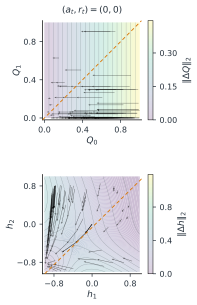

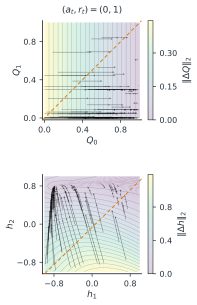

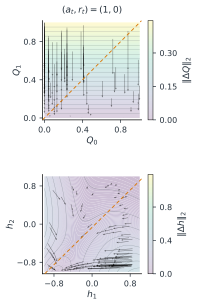

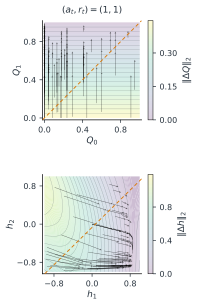

In [23]:
fields = {}
for model_name, model in models.items():
    state_limits = (0.0, 1.0) if model_name == "RW" else (-1.0, 1.0)
    fields[model_name] = compute_model_dynamics(
        model=model,
        records=records,
        model_name=model_name,
        grid_size=GRID_SIZE,
        state_limits=state_limits,
        max_arrows_per_condition=MAX_ARROWS_PER_CONDITION,
        sample_seed=DYNAMICS_SAMPLE_SEED,
    )

plot_dynamics_comparison(fields, FIGURE_DIR)
for action in (0, 1):
    for reward in (0, 1):
        show_svg(FIGURE_DIR / f"dynamics_a{action}r{reward}.svg")

**图 2　整个测试集的条件状态动力学。** 每张图对应一种动作与奖励组合，上为 RW、下为 GRU。黑箭头为实际反馈驱动的更新，背景颜色与细等值线表示该条件下状态更新幅度，橙色虚线为等概率决策边界。

每个面板固定一种动作与奖励条件。黑箭头表示真实测试历史驱动的模型更新，箭头起点和终点分别对应反馈前后的状态。背景颜色与细等值线表示假设状态下的更新幅度 $\|F_{a,r}(\mathbf s)-\mathbf s\|$。等值线连接幅度相同的位置，并不表示随时间发展的轨迹；背景网格也不意味着所有位置均被实际访问。

橙色虚线表示两个动作等概率的状态。RW 的边界为 $Q(0)=Q(1)$，GRU 的边界由拟合后的线性读出参数决定。状态相对边界的移动有助于解释选择偏好的变化。

同一模型的四个面板共用幅度色标。由于 Q 值与 GRU 隐藏状态的坐标单位不同，跨模型比较时应考察选择概率的变化，而不直接依据颜色或箭头长度判断学习速度。

## 参考文献

Ji-An, L., Benna, M. K., & Mattar, M. G. (2025). Discovering cognitive strategies with tiny recurrent neural networks. *Nature, 644*, 993–1001. [doi:10.1038/s41586-025-09142-4](https://doi.org/10.1038/s41586-025-09142-4)

Bartolo, R., Saunders, R. C., Mitz, A. R., & Averbeck, B. B. (2020). Dimensionality, information and learning in prefrontal cortex. *PLOS Computational Biology, 16*(4), e1007514. [doi:10.1371/journal.pcbi.1007514](https://doi.org/10.1371/journal.pcbi.1007514)

Bartolo, R., & Averbeck, B. (2022). *Spike count data for studying dimensionality, information and learning in prefrontal cortex* [Data set, Version 1]. Mendeley Data. [doi:10.17632/p7ft2bvphx.1](https://doi.org/10.17632/p7ft2bvphx.1)